# 02 Shuffling-Varianten

Dieses Notebook zeigt, was die fünf Varianten mit der Reihenfolge der Trainingsdaten machen, prüft die Implementierung auf echten Daten und vergleicht A und C in einem kurzen Training.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn.functional as F
from matplotlib.colors import ListedColormap

from batch_shuffling_regularization.data import load_mnist
from batch_shuffling_regularization.experiment import EXPERIMENT_VARIANTS, RESULTS_DIR, Variant
from batch_shuffling_regularization.model import build_mlp
from batch_shuffling_regularization.shuffling import VARIANTS
from batch_shuffling_regularization.training import TrainConfig, get_device, make_deterministic, train

# A fixed style, so the figures look the same in every IDE theme and in headless runs.
plt.style.use("default")
FIG_DIR = RESULTS_DIR.parent / "figures"

make_deterministic()
device = get_device()

## Die Varianten

Ausgangspunkt ist immer dieselbe feste Aufteilung des Trainingssets in Batches (Datenpunkt 0-99 in Batch 1, 100-199 in Batch 2, ...). Die Varianten unterscheiden sich darin, was davon sich von Epoche zu Epoche ändert.

| Variante | Funktion | Was passiert vor jeder Epoche | Batch-Zusammensetzung | Reihenfolge der Batches | Reihenfolge im Batch |
|---|---|---|---|---|---|
| A | `no_shuffle` | nichts, immer die Original-Reihenfolge | fest | fest | fest |
| B | `shuffle_batch_order` | die festen Batches werden in eine neue Reihenfolge gebracht | fest | neu | fest |
| C | `shuffle_within_batches` | innerhalb jedes Batches werden die Datenpunkte gemischt | fest | fest | neu |
| D | `full_reshuffle` | der ganze Datensatz wird gemischt, dann neu in Batches geschnitten | neu | neu | neu |
| E | `no_shuffle` auf `sort_train_by_class` | wie A, aber das Trainingsset ist nach Ziffern sortiert (erst alle Nullen, dann alle Einsen, ...) | fest | fest | fest |

Die Funktionen A-D stehen in `shuffling.py`. E ist keine eigene Batch-Order-Funktion, sondern ändert die Daten selbst (`sort_train_by_class` in `data.py`); die Zuordnung steht in `EXPERIMENT_VARIANTS` in `experiment.py`.

Folgerungen:

- **C ist mathematisch dasselbe wie A.** Der Gradient eines Batches ist der Mittelwert über seine Datenpunkte, und der hängt nicht von deren Reihenfolge ab. Unterschiede entstehen nur durch Rundung bei der Gleitkomma-Summation. C dient deshalb als Kontrolle.
- **B und C zusammen sind dasselbe wie B.** Nur D erzeugt in jeder Epoche neue Batches.
- **E ist der Extremfall einer ungünstigen Reihenfolge.** Fast jeder Batch enthält nur eine Klasse, und am Ende jeder Epoche hat das Modell zuletzt nur Neunen gesehen.

Hilfsfunktion: liefert für eine Variante die Indizes einer Epoche bezogen auf das *unsortierte* Trainingsset. Für E werden die Positionen im sortierten Set über `sort_idx` auf die Original-Indizes zurückgerechnet.

In [2]:
def epoch_order(variant: Variant, n: int, batch_size: int, gen: torch.Generator, sort_idx: torch.Tensor) -> torch.Tensor:
    order = variant.batch_order(n, batch_size, gen)
    return sort_idx[order] if variant.sort_by_class else order

## Visualisierung an einem Mini-Datensatz

20 Datenpunkte mit je 4 Bildern aus 5 Klassen, Batchgröße 4, also 5 Schritte pro Epoche. Jede Spalte ist eine Variante, oben Epoche 1, unten Epoche 2. Jede Zeile ist ein Trainingsschritt, die Zahl ist der Index des Datenpunkts. Die Farbe zeigt, zu welchem Batch der Datenpunkt in der Original-Aufteilung gehört. Bei E steht rechts zusätzlich die Klasse des Batches.

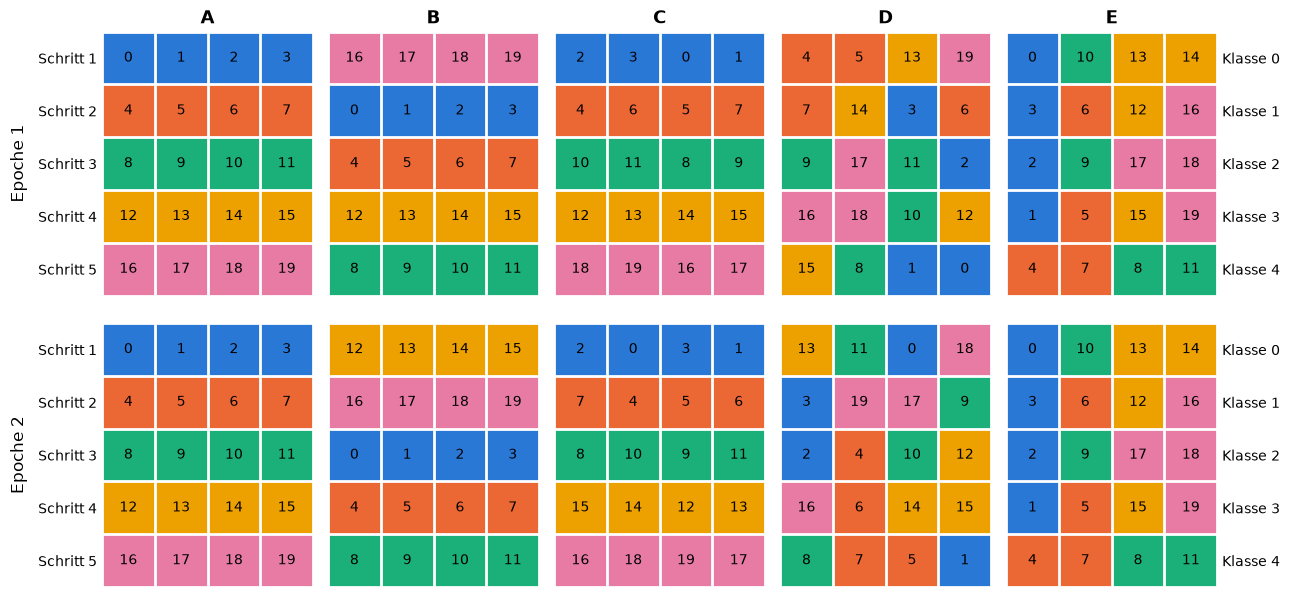

In [3]:
toy_n, toy_bs = 20, 4
toy_labels = torch.randperm(toy_n, generator=torch.Generator().manual_seed(1)) % 5
toy_sort_idx = toy_labels.argsort(stable=True)
cmap = ListedColormap(["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"])

fig, axes = plt.subplots(2, len(EXPERIMENT_VARIANTS), figsize=(13, 6.2))
for col, variant in enumerate(EXPERIMENT_VARIANTS):
    gen = torch.Generator().manual_seed(0)
    for epoch in range(2):
        order = epoch_order(variant, toy_n, toy_bs, gen, toy_sort_idx)
        n_steps = order.shape[0]
        ax = axes[epoch, col]
        ax.imshow(order // toy_bs, cmap=cmap, vmin=0, vmax=toy_n // toy_bs - 1)
        for step in range(n_steps):
            for pos in range(toy_bs):
                ax.text(pos, step, order[step, pos].item(), ha="center", va="center", fontsize=10)
        ax.set_xticks([x - 0.5 for x in range(toy_bs + 1)], minor=True)
        ax.set_yticks([y - 0.5 for y in range(n_steps + 1)], minor=True)
        ax.grid(which="minor", color="white", lw=2)
        ax.tick_params(which="both", length=0)
        ax.set_xticks([])
        if col == 0:
            ax.set_yticks(range(n_steps), [f"Schritt {s + 1}" for s in range(n_steps)])
            ax.set_ylabel(f"Epoche {epoch + 1}", fontsize=12, labelpad=8)
        elif variant.sort_by_class:
            ax.yaxis.tick_right()
            ax.set_yticks(range(n_steps), [f"Klasse {toy_labels[order[s, 0]].item()}" for s in range(n_steps)])
        else:
            ax.set_yticks([])
        if epoch == 0:
            ax.set_title(variant.name, fontsize=13, fontweight="bold")
        for spine in ax.spines.values():
            spine.set_visible(False)
plt.tight_layout()
fig.savefig(FIG_DIR / "toy_shuffling.png", dpi=150, bbox_inches="tight")
plt.show()

So liest man das Bild:

- **A**: beide Epochen sind identisch.
- **B**: jede Zeile ist einfarbig, die Batches bleiben also erhalten. Nur die Reihenfolge der Zeilen ändert sich.
- **C**: Zeilen und Farben stehen wie bei A, nur die Zahlen innerhalb einer Zeile tauschen die Plätze.
- **D**: die Farben sind gemischt, jeder Batch enthält Datenpunkte aus verschiedenen Original-Batches, und in Epoche 2 sieht es wieder anders aus.
- **E**: die Original-Batches sind zerrissen, dafür enthält jeder Batch nur eine Klasse. Beide Epochen sind identisch, wie bei A.

## Prüfung auf den echten Trainingsdaten

50.000 Datenpunkte, Batchgröße 100. Für jede Variante werden zwei Epochen erzeugt und verglichen:

- **Permutation**: jede Epoche enthält jeden Datenpunkt genau einmal.
- **Batches erhalten**: Anteil der Batches in Epoche 2, die (als Menge) schon in Epoche 1 vorkamen.
- **Batch an gleicher Stelle**: Anteil der Schritte, in denen derselbe Batch an derselben Position steht.
- **Index an gleicher Stelle**: Anteil der Einträge, die exakt gleich sind.
- **Klassen pro Batch**: wie viele verschiedene Ziffern ein Batch im Mittel enthält (Epoche 1).

In [4]:
data = load_mnist(device)
labels = data.train.y.cpu()
sort_idx = labels.argsort(stable=True)
n, batch_size = len(labels), 100

def batch_sets(order: torch.Tensor) -> list[tuple[int, ...]]:
    return [tuple(row) for row in order.sort(dim=1).values.tolist()]

orders = {}
rows = []
for variant in EXPERIMENT_VARIANTS:
    gen = torch.Generator().manual_seed(0)
    epoch_1 = epoch_order(variant, n, batch_size, gen, sort_idx)
    epoch_2 = epoch_order(variant, n, batch_size, gen, sort_idx)
    orders[variant.name] = epoch_1
    sets_1, sets_2 = batch_sets(epoch_1), batch_sets(epoch_2)
    rows.append({
        "Variante": variant.name,
        "Permutation": all(torch.equal(e.flatten().sort().values, torch.arange(n)) for e in (epoch_1, epoch_2)),
        "Batches erhalten": sum(s in set(sets_1) for s in sets_2) / len(sets_2),
        "Batch an gleicher Stelle": sum(a == b for a, b in zip(sets_1, sets_2)) / len(sets_2),
        "Index an gleicher Stelle": (epoch_1 == epoch_2).float().mean().item(),
        "Klassen pro Batch": sum(len(row.unique()) for row in labels[epoch_1]) / len(epoch_1),
    })
pd.DataFrame(rows).set_index("Variante").round(4)

,Permutation,Batches erhalten,Batch an gleicher Stelle,Index an gleicher Stelle,Klassen pro Batch
Variante,,,,,
A,True,1.0,1.000,1.0000,10.000
B,True,1.0,0.002,0.0020,10.000
C,True,1.0,1.000,0.0092,10.000
D,True,0.0,0.000,0.0000,10.000
E,True,1.0,1.000,1.0000,1.018


Erwartung: A und E überall 1, weil sich zwischen den Epochen nichts ändert. B erhält alle Batches, aber kaum einer steht an derselben Stelle. C erhält Batches und deren Position, aber nur ca. 1 % der Einträge (1/Batchgröße) bleibt zufällig auf seinem Platz. D erhält praktisch nichts. Bei A-D enthält ein Batch fast alle 10 Ziffern, bei E fast immer nur eine.

## Was das Modell in einer Epoche sieht

Für jeden der 500 Trainingsschritte einer Epoche: wie viele Bilder jeder Ziffer im Batch sind. Bei A-D sind die Klassen in jedem Schritt gleichmäßig verteilt, auch die rohe MNIST-Reihenfolge (A) ist also schon gut gemischt. E zeigt die Treppe: 50 Schritte lang nur Nullen, dann nur Einsen und so weiter.

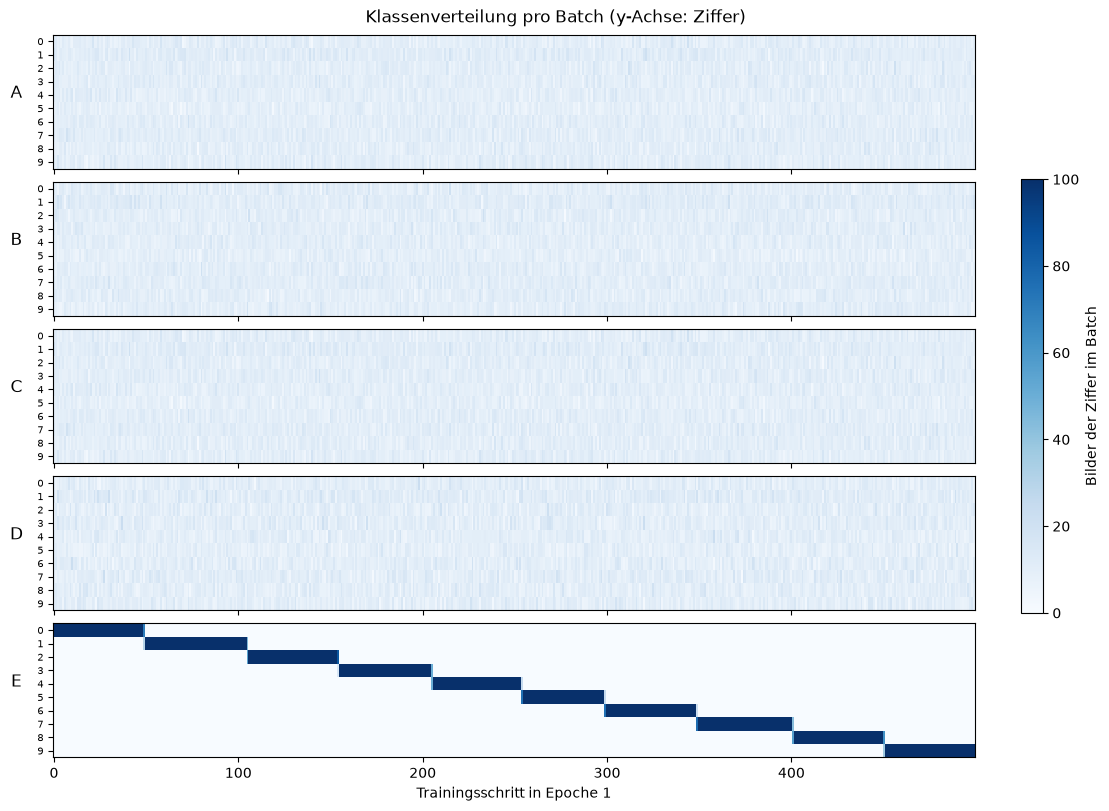

In [5]:
fig, axes = plt.subplots(len(orders), 1, figsize=(11, 8), sharex=True, layout="constrained")
for ax, (name, order) in zip(axes, orders.items()):
    counts = F.one_hot(labels[order], num_classes=10).sum(dim=1).T
    image = ax.imshow(counts, aspect="auto", cmap="Blues", vmin=0, vmax=batch_size, interpolation="nearest")
    ax.set_yticks(range(10))
    ax.set_ylabel(name, rotation=0, labelpad=15, fontsize=12)
    ax.tick_params(axis="y", labelsize=7)
axes[-1].set_xlabel("Trainingsschritt in Epoche 1")
fig.colorbar(image, ax=axes, label="Bilder der Ziffer im Batch", shrink=0.6)
fig.suptitle("Klassenverteilung pro Batch (y-Achse: Ziffer)")
fig.savefig(FIG_DIR / "class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## Kontrolle: Ist C wirklich gleich A?

Drei Trainingsläufe mit identischer Initialisierung (Seed 0), 30 Epochen: A, C und zum Vergleich D. Wenn die Überlegung oben stimmt, sollte der Abstand zwischen A und C deutlich kleiner sein als der zwischen A und D. E ist hier nicht dabei; ihre Ergebnisse kommen mit dem vollen Experiment.

In [6]:
cfg = TrainConfig()
runs = {name: train(build_mlp(seed=0, device=device), data, VARIANTS[name], cfg, order_seed=0) for name in ["A", "C", "D"]}

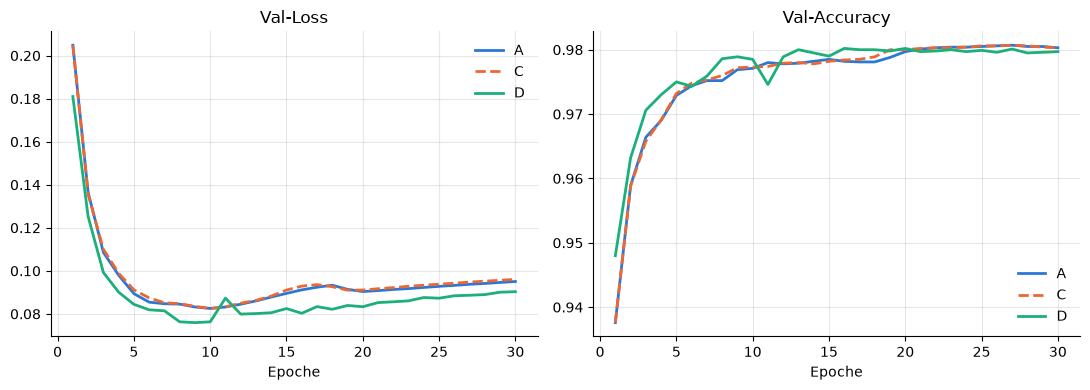

In [7]:
colors = {"A": "#2a78d6", "C": "#eb6834", "D": "#1baf7a"}
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(11, 4))
for name, history in runs.items():
    style = "--" if name == "C" else "-"
    ax_loss.plot(history.index[1:], history["val_loss"].iloc[1:], style, color=colors[name], lw=2, label=name)
    ax_acc.plot(history.index[1:], history["val_acc"].iloc[1:], style, color=colors[name], lw=2, label=name)
ax_loss.set(title="Val-Loss", xlabel="Epoche")
ax_acc.set(title="Val-Accuracy", xlabel="Epoche")
for ax in (ax_loss, ax_acc):
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
plt.tight_layout()

In [8]:
metrics = ["train_loss", "val_loss", "val_acc", "test_acc"]
pd.DataFrame({
    "max |C - A|": (runs["C"][metrics] - runs["A"][metrics]).abs().max(),
    "max |D - A|": (runs["D"][metrics] - runs["A"][metrics]).abs().max(),
})

,max |C - A|,max |D - A|
train_loss,0.001345,0.027002
val_loss,0.001981,0.023862
val_acc,0.001200,0.010400
test_acc,0.001200,0.011600
